# 04 - Doce meses de licitaciones: tendencias y contraste del puntaje con resultados reales

Los notebooks anteriores trabajan con una muestra de pocos días y no pueden responder dos preguntas:

1. **¿Cómo se comporta el mercado a lo largo de un año?**
2. **¿El puntaje de oportunidad destaca licitaciones que después tienen mejores resultados?**

Para responderlas se usa el histórico de datos abiertos de ChileCompra: todas las licitaciones publicadas entre abril de 2025 y marzo de 2026, con su estado final y el número de oferentes que recibieron.

**Requisito:** el archivo por licitación pesa 5,2 MB y no se versiona. Se genera en un par de minutos, sin ticket de la API:

```bash
python scripts/build_historico.py --desde 2025-04 --hasta 2026-03
```

**Dos límites de estos datos:**

- Solo incluyen licitaciones que recibieron **al menos una oferta**. Las que quedaron sin oferentes no aparecen.
- Los montos adjudicados del origen tienen errores de digitación graves (valores de billones de billones), así que no se usan. Los resultados que sí se usan son el estado final y el número de oferentes.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

sys.path.insert(0, "..")

from app.services.historico import AWARDED_STATE_CODE, monthly_summary
from app.services.keywords import DEFAULT_INDUSTRIAL_WORDS, compile_keywords, count_keywords, normalize_text
from app.services.scoring import score_licitaciones

HISTORY_PATH = Path("../data/historico/licitaciones.csv.gz")
ASSETS_DIR = Path("../assets")
SEED = 42

if not HISTORY_PATH.exists():
    raise FileNotFoundError("Falta data/historico/licitaciones.csv.gz. Genéralo con scripts/build_historico.py.")

history = pd.read_csv(HISTORY_PATH, parse_dates=["fecha_publicacion", "fecha_cierre"])
history["adjudicada"] = history["codigo_estado"].eq(AWARDED_STATE_CODE)

print(f"Licitaciones: {len(history):,}".replace(",", "."))
print(f"Publicadas entre {history['fecha_publicacion'].min():%Y-%m-%d} y {history['fecha_publicacion'].max():%Y-%m-%d}")
print(f"Organismos: {history['organismo_nombre'].nunique():,}   Rubros: {history['rubro_principal'].nunique()}".replace(",", "."))
print(f"Con monto estimado: {history['monto_estimado'].notna().mean():.1%}")
(history["estado"].value_counts(normalize=True) * 100).round(1).rename("% de licitaciones").to_frame()

Licitaciones: 100.124
Publicadas entre 2025-04-01 y 2026-03-31
Organismos: 1.074   Rubros: 58
Con monto estimado: 99.9%


,% de licitaciones
estado,
Adjudicada,80.8
Desierta (o art. 3 ó 9 Ley 19.886),12.8
Cerrada,3.7
Revocada,2.5
Suspendida,0.0


## 1. Tendencias mensuales

In [2]:
monthly = monthly_summary(history).set_index("mes")
monthly["pct_cerradas_sin_resolver"] = (
    history.assign(mes=history["fecha_publicacion"].dt.to_period("M").astype(str))
    .groupby("mes")["estado"]
    .apply(lambda states: (states == "Cerrada").mean() * 100)
)
monthly.round(1)

,licitaciones,pct_adjudicadas,mediana_oferentes,con_monto_clp,monto_total_mm,mediana_monto_mm,pct_cerradas_sin_resolver
mes,,,,,,,
2025-04,9383,80.7,3.0,9095,1608611.3,30.0,1.4
2025-05,8725,81.4,3.0,8457,1695431.6,29.0,1.6
2025-06,8711,79.7,3.0,8469,1461831.3,30.0,1.6
2025-07,9354,79.8,3.0,9073,1827200.9,28.5,1.7
2025-08,8722,81.3,3.0,8442,2213932.4,29.0,1.8
2025-09,7879,80.1,3.0,7607,4213772.7,30.0,2.5
2025-10,9043,79.9,3.0,8735,1764957.8,28.0,3.1
2025-11,8627,79.7,3.0,8392,1876839.1,28.6,4.4
2025-12,7070,76.2,3.0,6860,2555845.1,36.6,7.5


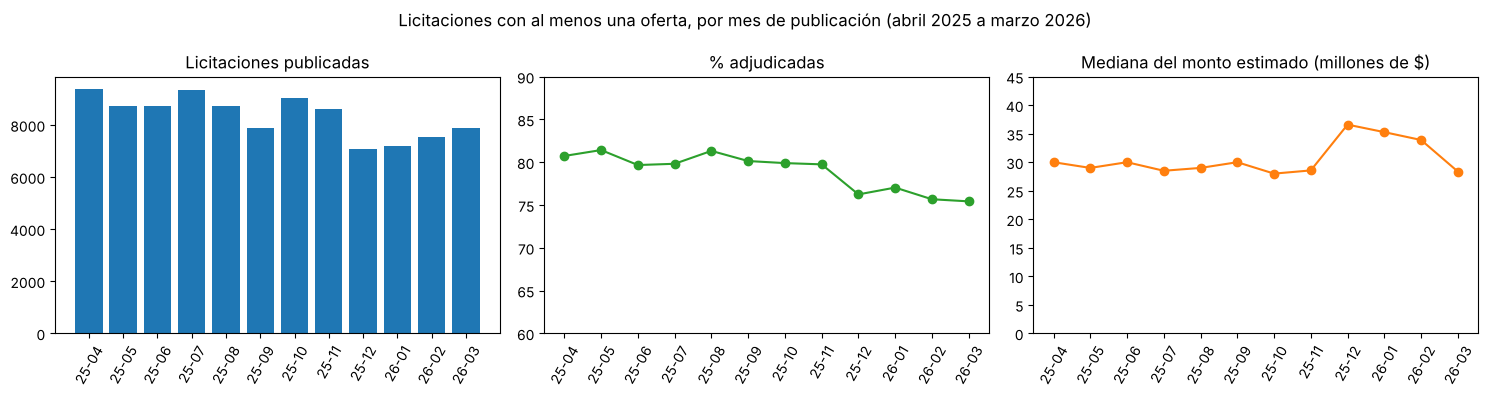

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels = [month[2:] for month in monthly.index]

axes[0].bar(labels, monthly["licitaciones"], color="#1f77b4")
axes[0].set_title("Licitaciones publicadas")
axes[1].plot(labels, monthly["pct_adjudicadas"], marker="o", color="#2ca02c")
axes[1].set_title("% adjudicadas")
axes[1].set_ylim(60, 90)
axes[2].plot(labels, monthly["mediana_monto_mm"], marker="o", color="#ff7f0e")
axes[2].set_title("Mediana del monto estimado (millones de $)")
axes[2].set_ylim(0, 45)
for ax in axes:
    ax.tick_params(axis="x", rotation=60)
fig.suptitle("Licitaciones con al menos una oferta, por mes de publicación (abril 2025 a marzo 2026)")
fig.tight_layout()
fig.savefig(ASSETS_DIR / "tendencia_mensual.png", dpi=150)
plt.show()

**Lectura.**

- **Volumen.** Se publican entre 7.070 (diciembre) y 9.383 (abril) licitaciones con ofertas al mes. Los meses de verano (diciembre a febrero) son los más bajos. Con un solo año no se puede separar estacionalidad de tendencia: la baja podría repetirse cada verano o ser un cambio de nivel.
- **Tamaño típico.** La mediana del monto estimado se mueve entre $28 y $37 millones, coherente con los $24,6 millones de la muestra de abril de 2026. Es más alta de diciembre a febrero.
- **Tasa de adjudicación.** Ronda el 80 % entre abril y noviembre y baja al 75-77 % desde diciembre. **Esa baja es en buena parte un efecto de madurez de los datos**: en los meses recientes más licitaciones siguen en estado "Cerrada", es decir, sin resolver (7 % desde diciembre, frente a menos de 2 % hasta agosto). No debe leerse como que se adjudica menos.
- **Competencia.** La mediana es de 3 oferentes todos los meses.
- Los montos totales por mes no se interpretan: están dominados por unas pocas licitaciones enormes (septiembre suma cerca del doble que los meses vecinos).

## 2. ¿El puntaje por reglas distingue licitaciones con mejores resultados?

El puntaje se calcula **como se habría visto el día de la publicación**: en ese momento toda licitación está publicada y abierta, así que esas dos reglas suman lo mismo para todas. Lo que diferencia a una licitación de otra son las palabras clave, el monto y la región. Se usa el perfil de ejemplo y, como en la muestra pública, las palabras se buscan solo en el nombre.

Después se compara, por nivel de prioridad, lo que ocurrió de verdad: si la licitación se adjudicó y cuántos oferentes tuvo.

In [4]:
at_publication = history.assign(
    codigo_estado=5,  # el día de la publicación toda licitación está publicada...
    fecha_cierre=pd.Timestamp("2100-01-01"),  # ...y abierta
)
scored = score_licitaciones(at_publication, reference_date="2000-01-01")
scored["estado_final"] = history["codigo_estado"].to_numpy()
scored["adjudicada"] = history["adjudicada"].to_numpy()
scored["desierta"] = scored["estado_final"].eq(7)
scored["monto_mm"] = scored["monto_estimado"].where(scored["moneda"] == "CLP") / 1_000_000

by_priority = scored.groupby("prioridad")
contrast = pd.DataFrame(
    {
        "Licitaciones": by_priority.size(),
        "% del total": by_priority.size() / len(scored) * 100,
        "% adjudicadas": by_priority["adjudicada"].mean() * 100,
        "% desiertas": by_priority["desierta"].mean() * 100,
        "Oferentes (mediana)": by_priority["numero_oferentes"].median(),
        "Oferentes (media)": by_priority["numero_oferentes"].mean(),
        "Monto mediano (millones de $)": by_priority["monto_mm"].median(),
    }
).reindex(["alta", "media", "baja"])
contrast.round(1)

,Licitaciones,% del total,% adjudicadas,% desiertas,Oferentes (mediana),Oferentes (media),Monto mediano (millones de $)
prioridad,,,,,,,
alta,8495,8.5,76.2,15.4,3.0,3.5,42.2
media,71289,71.2,79.5,12.2,3.0,4.6,44.8
baja,20340,20.3,78.9,14.1,3.0,4.4,6.6


**Lectura.**

- **Los niveles de prioridad casi no discriminan.** Vistas el día de su publicación, el 71,2 % de las licitaciones queda en prioridad media: toda licitación parte con 30 puntos por estar publicada y abierta, y con solo superar el umbral de monto llega a 40. La prioridad media significa, en la práctica, "supera los $10 millones".
- **La prioridad alta no tiene mejores resultados.** Se adjudica el 76,2 % de las de prioridad alta, frente al 79,5 % de las de media y el 78,9 % de las de baja, y queda desierta una proporción algo mayor (15,4 %). La mediana de oferentes es 3 en los tres niveles.
- Lo único que cambia entre niveles es el monto, y eso es por construcción: el monto es una de las reglas.

**El puntaje por reglas no identifica licitaciones con mejores resultados.** Ordena por parecido con el perfil (palabras clave, tamaño y región), que es para lo que fue escrito, pero ese orden no se relaciona con que la licitación se adjudique ni con cuánta competencia tiene.

### ¿Las palabras clave encuentran el rubro que buscan?

Cada licitación trae un rubro oficial, asignado por el organismo comprador según el clasificador de productos. Sirve como referencia independiente: si el perfil de ejemplo busca servicios industriales y de construcción, sus palabras clave deberían encontrar sobre todo licitaciones del rubro **Servicios de construcción y mantenimiento**.

- **Precisión:** de las licitaciones con alguna palabra clave, qué parte es de ese rubro.
- **Cobertura:** de las licitaciones de ese rubro, qué parte tiene alguna palabra clave.

In [5]:
TARGET_CATEGORY = "SERVICIOS DE CONSTRUCCIÓN Y MANTENIMIENTO"

has_keyword = scored["contiene_keyword"]
in_target = scored["rubro_principal"].eq(TARGET_CATEGORY)

print(f"Licitaciones con alguna palabra clave: {int(has_keyword.sum()):,}".replace(",", "."))
print(f"Licitaciones del rubro objetivo:       {int(in_target.sum()):,}".replace(",", "."))
print(f"Precisión: {(has_keyword & in_target).sum() / has_keyword.sum():.1%}")
print(f"Cobertura: {(has_keyword & in_target).sum() / in_target.sum():.1%}")

normalized_names = scored["nombre"].fillna("").map(normalize_text)
rows = []
for word in DEFAULT_INDUSTRIAL_WORDS:
    pattern = compile_keywords([word])
    matches = normalized_names.map(lambda text: count_keywords(text, pattern) > 0)
    rows.append(
        {
            "Palabra clave": word,
            "Licitaciones": int(matches.sum()),
            "% en el rubro objetivo": (matches & in_target).sum() / max(matches.sum(), 1) * 100,
        }
    )
pd.DataFrame(rows).set_index("Palabra clave").sort_values("Licitaciones", ascending=False).round(1)

Licitaciones con alguna palabra clave: 10.474
Licitaciones del rubro objetivo:       10.621
Precisión: 36.0%
Cobertura: 35.5%


,Licitaciones,% en el rubro objetivo
Palabra clave,,
mantencion,4782,25.7
reparacion,2597,40.6
construccion,2359,51.9
obra,1054,54.8
electrico,715,27.0
industrial,177,7.9
montaje,124,14.5
campamento,66,22.7
instrumentacion,6,0.0


In [6]:
(scored.loc[has_keyword, "rubro_principal"].value_counts(normalize=True).head(6) * 100).round(1).rename(
    "% de las licitaciones con palabra clave"
).to_frame()

,% de las licitaciones con palabra clave
rubro_principal,
SERVICIOS DE CONSTRUCCIÓN Y MANTENIMIENTO,36.0
"SERVICIOS PROFESIONALES, ADMINISTRATIVOS Y CONSULTORÍAS DE GESTIÓN EMPRESARIAL",6.3
"SERVICIOS DE TRANSPORTE, ALMACENAJE Y CORREO",5.3
SERVICIOS DE PRODUCCIÓN Y FABRICACIÓN INDUSTRIAL,5.2
"ARTÍCULOS PARA ESTRUCTURAS, OBRAS Y CONSTRUCCIONES",4.9
VEHÍCULOS Y EQUIPAMIENTO EN GENERAL,3.9


**Lectura.**

- **Precisión del 36,0 % y cobertura del 35,5 %.** De cada tres licitaciones que las palabras clave marcan, solo una es del rubro de construcción y mantenimiento; y de cada tres licitaciones de ese rubro, las palabras clave encuentran una.
- Las palabras más específicas funcionan mejor ("obra" 54,8 %, "construcción" 51,9 %). La más frecuente, "mantención", es la que más ruido trae (25,7 %): aparece en mantención de vehículos, de equipos médicos o de software.
- "Industrial" casi nunca corresponde al rubro (7,9 %) e "instrumentación" no aparece prácticamente nunca (6 licitaciones en un año).

Como filtro de relevancia, **el rubro oficial es una señal mejor que las palabras clave en el nombre**: está disponible para todas las licitaciones y no depende de cómo se redactó el título. Por eso el perfil del puntaje admite ahora una lista de rubros objetivo, además de las palabras clave.

## 3. Una señal que sí se puede aprender de los datos: la competencia esperada

Los pesos del puntaje son de criterio. El histórico permite reemplazar al menos una parte por algo medido: **cuánta competencia se puede esperar en una licitación, sabiendo solo lo que se conoce el día en que se publica**.

- **Objetivo:** que la licitación reciba **2 oferentes o menos** (poca competencia).
- **Variables:** rubro, región, sector del organismo, tipo de licitación, monto estimado (en logaritmo), número de ítems y días entre la publicación y el cierre. Todas se conocen al publicar.
- **Partición temporal:** se entrena con las licitaciones publicadas de abril a diciembre de 2025 y se prueba con las de enero a marzo de 2026. Es como se usaría en la práctica: aprender del pasado para puntuar lo que viene.
- **Modelos base:** la tasa global de poca competencia y la tasa histórica de cada rubro.

In [7]:
CUTOFF = "2026-01-01"
CATEGORICAL = ["rubro_principal", "region_unidad", "sector", "tipo"]
NUMERIC = ["log_monto", "cantidad_items", "dias_abierta"]

data = history.copy()
data["pocos_oferentes"] = (data["numero_oferentes"] <= 2).astype(int)
usable_amount = data["monto_estimado"].where((data["moneda"] == "CLP") & (data["monto_estimado"] >= 1000))
data["log_monto"] = np.log10(usable_amount).fillna(-1)  # -1 marca "sin monto en pesos"
data["dias_abierta"] = (data["fecha_cierre"] - data["fecha_publicacion"]).dt.days.clip(0, 120).fillna(-1)
data[CATEGORICAL] = data[CATEGORICAL].fillna("Sin dato")

train = data[data["fecha_publicacion"] < CUTOFF]
test = data[data["fecha_publicacion"] >= CUTOFF]

for label, part in (("Entrenamiento", train), ("Prueba", test)):
    months = f"{part['fecha_publicacion'].min():%Y-%m} a {part['fecha_publicacion'].max():%Y-%m}"
    print(f"{label}: {len(part)} licitaciones ({months}); {part['pocos_oferentes'].mean():.1%} con poca competencia")

Entrenamiento: 77514 licitaciones (2025-04 a 2025-12); 43.8% con poca competencia
Prueba: 22610 licitaciones (2026-01 a 2026-03); 44.8% con poca competencia


In [8]:
def encoder(sparse):
    return ColumnTransformer(
        [("categorias", OneHotEncoder(handle_unknown="ignore", min_frequency=30, sparse_output=sparse), CATEGORICAL)],
        remainder="passthrough",
    )


features = CATEGORICAL + NUMERIC
y_train, y_test = train["pocos_oferentes"], test["pocos_oferentes"]

global_rate = y_train.mean()
rate_by_category = train.groupby("rubro_principal")["pocos_oferentes"].mean()

logistic = make_pipeline(encoder(sparse=True), LogisticRegression(max_iter=2000)).fit(train[features], y_train)
boosting = make_pipeline(encoder(sparse=False), HistGradientBoostingClassifier(random_state=SEED)).fit(
    train[features], y_train
)

predictions = {
    "Base: tasa global": np.full(len(test), global_rate),
    "Base: tasa histórica del rubro": test["rubro_principal"].map(rate_by_category).fillna(global_rate).to_numpy(),
    "Regresión logística": logistic.predict_proba(test[features])[:, 1],
    "Gradient boosting": boosting.predict_proba(test[features])[:, 1],
}

results = pd.DataFrame(
    {
        name: {
            "ROC-AUC": roc_auc_score(y_test, probabilities),
            "PR-AUC": average_precision_score(y_test, probabilities),
            "Brier": brier_score_loss(y_test, probabilities),
        }
        for name, probabilities in predictions.items()
    }
).T
results.round(3)

,ROC-AUC,PR-AUC,Brier
Base: tasa global,0.500,0.448,0.247
Base: tasa histórica del rubro,0.618,0.544,0.237
Regresión logística,0.685,0.621,0.221
Gradient boosting,0.730,0.675,0.207


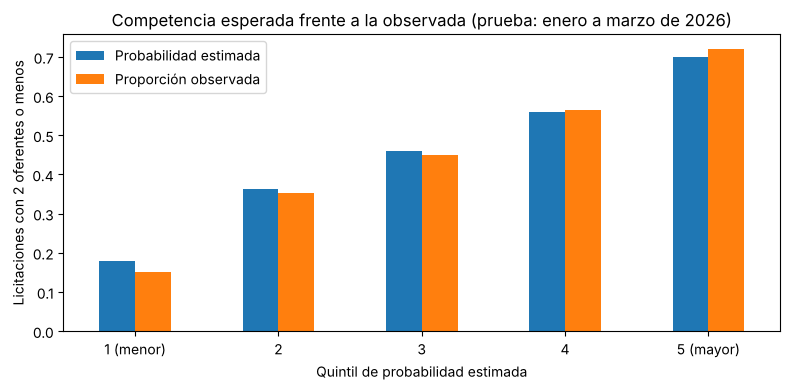

,Licitaciones,Probabilidad estimada,Proporción observada
Quintil de probabilidad estimada,,,
1 (menor),4525,0.179,0.151
2,4519,0.363,0.353
3,4522,0.460,0.450
4,4522,0.560,0.565
5 (mayor),4522,0.700,0.721


In [9]:
quintile = pd.qcut(predictions["Gradient boosting"], 5, labels=["1 (menor)", "2", "3", "4", "5 (mayor)"])
calibration = pd.DataFrame(
    {
        "Licitaciones": pd.Series(quintile).value_counts().sort_index(),
        "Probabilidad estimada": pd.Series(predictions["Gradient boosting"]).groupby(quintile, observed=True).mean(),
        "Proporción observada": y_test.reset_index(drop=True).groupby(quintile, observed=True).mean(),
    }
)
calibration.index.name = "Quintil de probabilidad estimada"

ax = calibration[["Probabilidad estimada", "Proporción observada"]].plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylabel("Licitaciones con 2 oferentes o menos")
ax.set_title("Competencia esperada frente a la observada (prueba: enero a marzo de 2026)")
plt.tight_layout()
plt.savefig(ASSETS_DIR / "competencia_calibracion.png", dpi=150)
plt.show()

calibration.round(3)

**Lectura.**

- **La competencia sí se puede anticipar.** El modelo de gradient boosting alcanza un ROC-AUC de 0,730 y un PR-AUC de 0,675 sobre tres meses que no vio al entrenar, frente a 0,448 de PR-AUC de la tasa global. Usar solo la tasa histórica del rubro ya aporta (ROC-AUC 0,618); el resto de las variables suma otro tramo.
- **Las probabilidades están bien calibradas.** En el quintil con menor probabilidad estimada (17,9 %) la proporción real fue de 15,1 %, y en el de mayor (70,0 %) fue de 72,1 %. Los tres quintiles intermedios difieren en un punto porcentual o menos.
- La diferencia entre extremos es grande: una licitación del quintil superior tiene casi cinco veces más probabilidad de recibir pocos oferentes que una del inferior.

**Qué no dice este modelo.** Poca competencia no es lo mismo que ganar: no hay datos sobre la capacidad de un proveedor concreto ni sobre los precios. Y como el histórico no incluye las licitaciones sin oferentes, el modelo describe la competencia entre las que sí recibieron ofertas.

### Tabla de competencia por rubro

La versión más simple de esta señal es una tabla por rubro, que el dashboard usa para mostrar, junto a cada licitación, la competencia típica de su rubro. Se calcula con los doce meses y se guarda en `data/historico/competencia_por_rubro.csv`.

In [10]:
by_category = data.groupby("rubro_principal")
competition = pd.DataFrame(
    {
        "licitaciones": by_category.size(),
        "mediana_oferentes": by_category["numero_oferentes"].median(),
        "pct_pocos_oferentes": by_category["pocos_oferentes"].mean() * 100,
        "pct_adjudicadas": by_category["adjudicada"].mean() * 100,
    }
)
competition = competition[competition["licitaciones"] >= 300].sort_values("pct_pocos_oferentes", ascending=False)
competition.round(1).to_csv("../data/historico/competencia_por_rubro.csv", encoding="utf-8")

print(f"Rubros con al menos 300 licitaciones: {len(competition)}")
pd.concat([competition.head(5), competition.tail(5)]).round(1)

Rubros con al menos 300 licitaciones: 49


,licitaciones,mediana_oferentes,pct_pocos_oferentes,pct_adjudicadas
rubro_principal,,,,
SERVICIOS BÁSICOS Y DE INFORMACIÓN PÚBLICA,1144,2.0,68.7,77.3
SERVICIOS DE PRODUCCIÓN Y FABRICACIÓN INDUSTRIAL,1818,2.0,62.0,76.3
"SERVICIOS FINANCIEROS, PENSIONES Y SEGUROS",1243,2.0,61.9,80.6
"SERVICIOS DE TRANSPORTE, ALMACENAJE Y CORREO",4742,2.0,61.2,77.5
"SERVICIOS DE VIAJES, ALIMENTACIÓN, ALOJAMIENTO Y ENTRETENIMIENTO",1701,2.0,61.1,81.8
"EQUIPOS, ACCESORIOS Y SUMINISTROS DE OFICINA",1187,5.0,24.5,81.0
HERRAMIENTAS Y MAQUINARIA EN GENERAL,393,5.0,23.7,74.6
CONSULTORIA,418,5.0,22.0,33.0
EQUIPOS Y SUMINISTROS DE LIMPIEZA,641,5.0,20.1,81.4


**Lectura.**

- La competencia cambia mucho según el rubro. En servicios básicos, producción industrial, servicios financieros y transporte, más del 60 % de las licitaciones recibe 2 oferentes o menos. En obras, insumos de limpieza y artículos de oficina es menos del 25 %, con una mediana de 5 oferentes.
- El rubro de construcción y mantenimiento, el más cercano al perfil de ejemplo, está en la zona media: 40,3 % con poca competencia, mediana de 3 oferentes y 76,3 % adjudicadas.
- Los rubros "Obras" y "Consultoría" se adjudican solo un tercio de las veces (32,3 % y 33,0 %) pese a recibir muchas ofertas. Puede ser un rasgo real de esos procesos o un efecto de cómo se registran sus etapas; no se investigó.

## 4. Conclusiones

1. **En un año, el mercado es estable en lo que importa para un proveedor**: entre 7.000 y 9.400 licitaciones con ofertas al mes, una mediana cercana a $30 millones y 3 oferentes de mediana. La baja de la tasa de adjudicación en los meses recientes es efecto de licitaciones aún sin resolver.
2. **El puntaje por reglas no se sostiene como predictor de resultados.** Sus niveles de prioridad casi no discriminan (71 % queda en media) y la prioridad alta no se adjudica más ni tiene menos competencia.
3. **Las palabras clave son un filtro de relevancia débil**: 36 % de precisión y 35,5 % de cobertura frente al rubro oficial. El rubro es mejor señal y ya se puede usar en el perfil.
4. **La competencia esperada sí se puede aprender de los datos**: con partición temporal, un modelo simple llega a un ROC-AUC de 0,73 con probabilidades bien calibradas. Es el reemplazo natural de los pesos arbitrarios: en vez de sumar puntos por reglas, estimar algo medible.

### Limitaciones

- El histórico solo incluye licitaciones con al menos una oferta; las desiertas por falta de oferentes no aparecen, lo que sesga hacia arriba la tasa de adjudicación y la competencia.
- Los estados de los meses recientes no son definitivos.
- "Poca competencia" es un resultado medible, pero no es el objetivo final de un proveedor (ganar con margen). No hay datos de costos, precios ni de qué proveedores podían postular.
- El modelo de competencia se evaluó con una sola partición temporal y sin ajuste de hiperparámetros. Está en este notebook como análisis; el dashboard usa solo la tabla por rubro.
- Un año no permite distinguir estacionalidad de tendencia.